### Dataset

**Descripción:** Esta dataset fue creado para el paper 'From Group to Individual Labels using Deep Features', Kotzias et. al,. KDD 2015. Sition web: Kotzias, D. (2015). Sentiment Labelled Sentences [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C57604.

**Para más informacíon:**
[Ficha técnica](../docs/ficha-tecnica.md)

## 23. U02.LAB05 · Clasificación de texto: TF-IDF, Naive Bayes y modelo lineal

In [14]:
# make models iside src importable here. For uv this does not matter,
# or when using .venv, but does matter when using global
from util import make_dir_modules_importable
make_dir_modules_importable()

#built-in modeules
import importlib
import pandas as pd
from gensim.models import Word2Vec # modelo de embeding de palabras
import networkx as nx # crea y analiza grafos
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
import joblib

#custom modules
import lab04_05.audit as audit_modeule
import lab04_05.data as data_modeule
import lab04_05.modeling as modeling_modeule

importlib.reload(data_modeule)
importlib.reload(audit_modeule)
importlib.reload(modeling_modeule)

#custom modules types
from lab04_05.data import Data
from lab04_05.audit import Audit
from lab04_05.modeling import build_models



Adding: /mnt/d/Documents/Ciencias de datos/Ciencia de datos 2/PRACTICAS/uasd-ds-2/unidad02/LAB04-05/src to sys.path


In [ ]:
# covnerting .txt file containing data to csv
# https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

data = Data()
data.tab_separatd_file_to_csv('raw/amazon_cells_labelled.txt', 'processed/amazon_cells_labelled.csv')
data.tab_separatd_file_to_csv('raw/imdb_labelled.txt', 'processed/imdb_labelled.csv')
data.tab_separatd_file_to_csv('raw/yelp_labelled.txt', 'processed/yelp_labelled.csv')

In [3]:
#load data
data = Data()

#reading data
amazon_dataset_file_path = data.get_file_path('processed/amazon_cells_labelled.csv')
amazon_dataset_df = pd.read_csv(amazon_dataset_file_path, sep="|")
amazon_dataset_df.head()

,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
#audit data
audit = Audit(amazon_dataset_df)
data.validate_dataframe(
    df=amazon_dataset_df,
    text_column="text",
    target_column="label"
)
print(audit)


- columns: ['text', 'label']
- shape: (1000, 2)
- shape: 10
- distribution: 
  label
0    0.5
1    0.5
Name: proportion, dtype: float64
-----------Summary------------------------
        tipo  ausentes
text     str         0
label  int64         0
-----------ongitudes de textos------------
0.00     11.0
0.25     26.0
0.50     48.0
0.75     77.0
1.00    149.0
Name: text, dtype: float64
------------------------------------------



In [16]:
amazon_dataset_df = amazon_dataset_df.dropna(subset=["text", "label"])
data.validate_dataframe(
    amazon_dataset_df, 
    text_column="text",
    target_column="label"
)
counts = amazon_dataset_df["label"].value_counts()
stratify = amazon_dataset_df["label"] if counts.min() >= 2 else None
print(counts)
print(counts.min())
print(stratify.head(10))

label
0    500
1    500
Name: count, dtype: int64
500
0    0
1    1
2    1
3    0
4    1
5    0
6    0
7    1
8    0
9    0
Name: label, dtype: int64


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    amazon_dataset_df["text"],
    amazon_dataset_df["label"],
    test_size=0.25, # 75 % para entrenar, 25 % para evaluar.
    random_state=42,
    stratify=stratify,
)
models = build_models()

In [12]:
rows = []
predictions = {}
for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    predictions[name] = pred
    score = f1_score(y_test, pred, average="macro")
    rows.append({"model": name, "f1_macro": score})

    print(f"\n{name} · F1 macro={score:.3f}")
    print(classification_report(y_test, pred, zero_division=0))


dummy · F1 macro=0.333
              precision    recall  f1-score   support

           0       0.50      1.00      0.67       125
           1       0.00      0.00      0.00       125

    accuracy                           0.50       250
   macro avg       0.25      0.50      0.33       250
weighted avg       0.25      0.50      0.33       250


naive_bayes · F1 macro=0.824
              precision    recall  f1-score   support

           0       0.83      0.82      0.82       125
           1       0.82      0.83      0.83       125

    accuracy                           0.82       250
   macro avg       0.82      0.82      0.82       250
weighted avg       0.82      0.82      0.82       250


logistic · F1 macro=0.832
              precision    recall  f1-score   support

           0       0.81      0.86      0.84       125
           1       0.85      0.80      0.83       125

    accuracy                           0.83       250
   macro avg       0.83      0.83      0.83    

In [13]:
ROOT_DIR = data.get_root_directory()
data.create_directory("models")
data.create_directory("reports")


Artefactos guardados en reports/ y models/


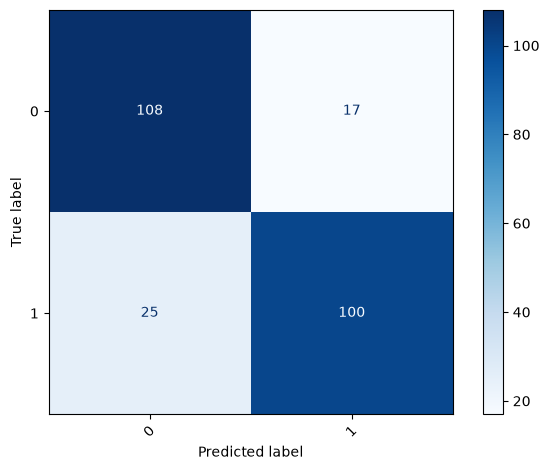

In [15]:
pd.DataFrame(rows).sort_values("f1_macro", ascending=False).to_csv(ROOT_DIR / "reports" / "text_metrics.csv", index=False)
selected = models["logistic"]
selected_pred = predictions["logistic"]
ConfusionMatrixDisplay.from_predictions(y_test, selected_pred, xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.savefig(ROOT_DIR / "reports" / "confusion_text.png", dpi=170)
errors = pd.DataFrame({"text": x_test, "real": y_test, "predicted": selected_pred})
errors = errors[errors["real"] != errors["predicted"]].copy()
errors["category"] = "REVISAR"
errors.to_csv(ROOT_DIR / "reports" / "error_analysis.csv", index=False)
joblib.dump(selected, ROOT_DIR / "models" / "text_model.joblib")
print("\nArtefactos guardados en reports/ y models/")